# Predict tomorrow’s energy — regression from first principles

## Goal
Build a prediction from a decision contract, not from an algorithm name. This is an executed tutorial using original synthetic data. **Do not infer real operational usefulness from these results.**

Prediction cutoff: 18:00 today. Target: tomorrow’s kWh. Unit: factory-day. Available inputs: temperature forecast index and approved production schedule. Baseline: training mean. Chronological 100/40/40 split.

## Setup
Extract the entire learning kit before opening this notebook. Install `requirements.txt` in a Python 3.12 virtual environment. No network or credentials are used during execution. Freeze and evaluate only after development choices are settled. The test-set guard is a learning convention, not secure access control.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from workshop import *
plt.rcParams.update({'figure.figsize': (8.5, 4.2), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18})
COLORS = {'actual': '#263a36', 'model': '#4c713d', 'baseline': '#82739b'}
SEED = 42
PROJECT = 'energy'
rows = make_dataset(PROJECT, SEED)
classification = PROJECT == 'maintenance'
UNITS = 'kWh/day' if PROJECT == 'energy' else 'packs/store-week' if PROJECT == 'demand' else 'probability'
train, validation, test = (partition(rows, part) for part in ('train','validation','test'))
print({part: len(partition(rows, part)) for part in ('train','validation','test')})

{'train': 100, 'validation': 40, 'test': 40}


## Steps
### 1. Inspect the grain and information cutoff
A row has an entity, an ordered time, available inputs, an outcome, and an assigned split. Inspect only training outcomes here. Original schema, timing, and licenses are documented in DATA.md.

In [2]:
print(json.dumps(train[:3], indent=2))
assert len({r['id'] for r in rows}) == len(rows)
assert all(np.isfinite(r['x']).all() and np.isfinite(r['y']) for r in rows)

[
  {
    "id": "day-0",
    "entity": "factory-A",
    "time": 0,
    "x": [
      -0.9906193008646369,
      -1.647499818354845
    ],
    "y": 44.46336949011311,
    "baseline": 92.70014407062904,
    "segment": "cooler days",
    "split": "train"
  },
  {
    "id": "day-1",
    "entity": "factory-A",
    "time": 1,
    "x": [
      -0.21087485644966364,
      -1.5261599849909544
    ],
    "y": 66.10525915725157,
    "baseline": 92.70014407062904,
    "segment": "cooler days",
    "split": "train"
  },
  {
    "id": "day-2",
    "entity": "factory-A",
    "time": 2,
    "x": [
      0.5680037857964635,
      1.4458247497677803
    ],
    "y": 121.72848096257076,
    "baseline": 92.70014407062904,
    "segment": "warmer days",
    "split": "train"
  }
]


### 2. Write a falsifiable hypothesis
**Pause:** write why these inputs should improve on the baseline. Name a plausible failure mechanism. An observation such as lower training loss will not prove this hypothesis.

Professional lenses: domain experts inspect the target/proxies; statisticians inspect the split; engineers inspect availability and reproducibility; owners inspect cost; reviewers look for optimistic evidence.

In [3]:
HYPOTHESIS = 'Available measurements and known plans may improve on a simple baseline.'
INTERPRETATION = ''  # Replace after viewing your frozen evaluation.
NEXT_ACTION = ''     # Owner, monitoring cadence, manual fallback, rollback trigger.
print(HYPOTHESIS)

Available measurements and known plans may improve on a simple baseline.


### 3. Establish a baseline before fitting
The baseline is the training mean (energy), training prevalence (maintenance), or the same store 12 synthetic weeks earlier (demand). The synthetic demand cycle has period 12; this is not a universal retail season.

In [4]:
x_train, y_train = arrays(train)
x_val, y_val = arrays(validation)
baseline_validation = metrics(y_val, np.array([r['baseline'] for r in validation]), classification)
print(json.dumps(baseline_validation, indent=2))

{
  "mae": 17.984277781279758,
  "rmse": 22.435099860617168,
  "bias": 2.996166108697659
}


### 4. One hand update, then a transparent algorithm
For standardized regression with x=2, target=1, intercept=0, weight=0: prediction=0, the weight gradient of half squared loss is −2. At learning rate 0.1, weight becomes 0.2. The full implementation adds an unpenalized intercept and optional ridge penalty. Logistic regression substitutes sigmoid probabilities and log loss.

{'gradient': -2.0, 'new_weight': 0.2}
{
  "mae": 2.4794957233793524,
  "rmse": 3.101997753718824,
  "bias": 0.4889562439937579
}


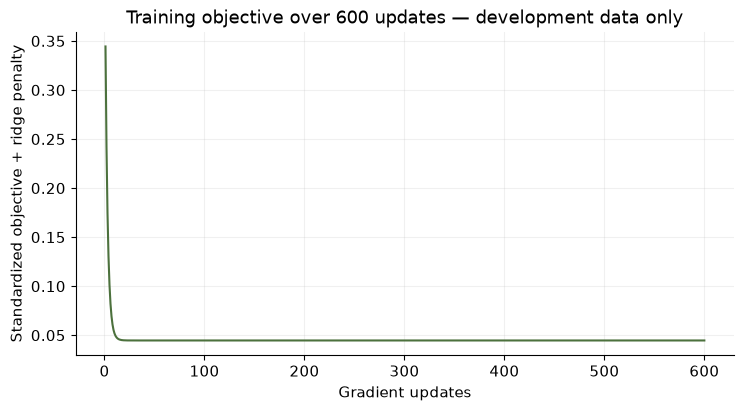

In [5]:
x, target, weight, rate = 2., 1., 0., .1
gradient_one = x * (weight * x - target)
print({'gradient': gradient_one, 'new_weight': weight - rate * gradient_one})
manual = manual_fit(train, classification, penalty=.1)
manual_validation = manual_predict(manual, validation)
print(json.dumps(metrics(y_val, manual_validation, classification), indent=2))
plt.plot(np.arange(1, len(manual['losses']) + 1), manual['losses'], color=COLORS['model'])
plt.title('Training objective over 600 updates — development data only')
plt.xlabel('Gradient updates'); plt.ylabel('Standardized objective + ridge penalty'); plt.show()

The curve is the optimized training objective, not a claim about test performance. Training statistics are fitted on the training partition only. A fixed seed reproduces a sample, not a guarantee of generalization.

### 5. Use a fitted preprocessing-plus-model pipeline
Keep the scaler and predictor together. `fit` sees training only; validation is transform/predict only. The ridge strength below is scaled to match the browser objective. Read `workshop.py` to connect the short library call to the transparent implementation.

In [6]:
pipeline = pipeline_for(classification, penalty=.1, n_train=len(train))
pipeline.fit(x_train, y_train)
validation_prediction = output(pipeline, x_val, classification)
print(json.dumps(metrics(y_val, validation_prediction, classification), indent=2))

{
  "mae": 2.4794957233793555,
  "rmse": 3.101997753718827,
  "bias": 0.48895624399376664
}


### 6. Try the plausible mistake: give the model its future outcome
This deliberate diagnostic adds y as an input on both training and validation rows. It cannot be supplied at prediction time. A dramatic apparent improvement is evidence of a broken protocol, not a superior deployable model.

In [7]:
leaked = manual_fit(train, classification, leak=True, penalty=0)
leaked_prediction = manual_predict(leaked, validation)
print('Honest validation:', metrics(y_val, manual_validation, classification))
print('Leaked validation:', metrics(y_val, leaked_prediction, classification))
# Deliberately discard the leaked model before any final evaluation.
del leaked, leaked_prediction

Honest validation: {'mae': 2.4794957233793524, 'rmse': 3.101997753718824, 'bias': 0.4889562439937579}
Leaked validation: {'mae': 0.7289021618009747, 'rmse': 0.8804337404090207, 'bias': 0.0906761820063819}


### 7. Compare a bounded development search
Five fixed candidates share the same train/validation observations. Trees, forests, and boosting can represent nonlinear patterns; complexity is useful only if honest evidence supports it. A ranking on this small synthetic validation sample has no automatic statistical significance.

In [8]:
comparisons = development_comparison(rows, classification)
for result in comparisons:
    print(result['model'], round(result['log_loss'] if classification else result['mae'], 4))

linear_or_logistic 2.2187
ridge_0.1 2.4795
one_split_tree 16.022
random_forest 4.0648
gradient_boosting 3.9214


**Decision record:** record which result surprised you, what assumption it challenges, and the next discriminating experiment. Do not choose a model by looking at final-test labels. The remaining cells use the predeclared ridge/logistic pipeline for teaching consistency; they do not pretend it won every search.

### 8. Diagnose residuals and subgroup sample sizes
An average can hide systematic error. Residual is prediction minus observed. A zero mean residual does not imply small individual errors.

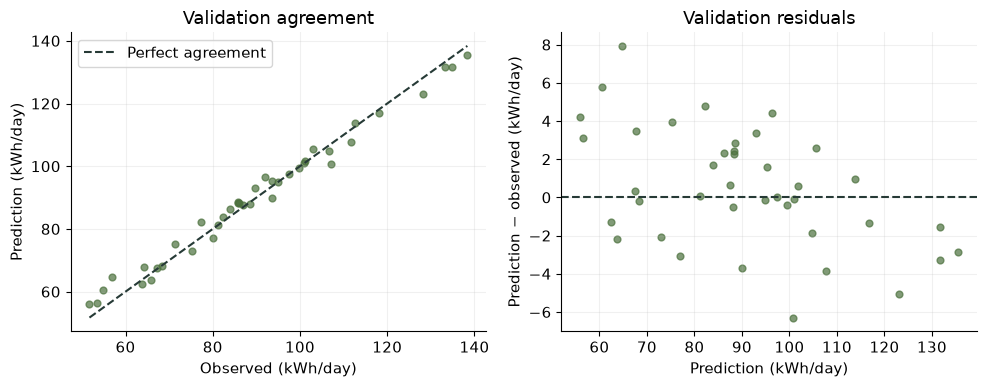

cooler days n= 24 {'mae': 1.9966388028006021, 'rmse': 2.690269935518766, 'bias': 0.8771137982061269}
warmer days n= 16 {'mae': 3.203781104247486, 'rmse': 3.6331317993237455, 'bias': -0.09328008732477366}


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10,4))
axes[0].scatter(y_val, validation_prediction, color=COLORS['model'], s=24, alpha=.7)
limits = [min(y_val.min(), validation_prediction.min()), max(y_val.max(), validation_prediction.max())]
axes[0].plot(limits, limits, '--', color=COLORS['actual'], label='Perfect agreement')
axes[0].set(xlabel=f'Observed ({UNITS})', ylabel=f'Prediction ({UNITS})', title='Validation agreement'); axes[0].legend()
axes[1].scatter(validation_prediction, validation_prediction-y_val, color=COLORS['model'], s=24, alpha=.7)
axes[1].axhline(0, color=COLORS['actual'], linestyle='--')
axes[1].set(xlabel=f'Prediction ({UNITS})', ylabel=f'Prediction − observed ({UNITS})', title='Validation residuals')
fig.tight_layout(); plt.show()
for segment in sorted({r['segment'] for r in validation}):
    sample=[r for r in validation if r['segment']==segment]
    x_slice, y_slice=arrays(sample)
    print(segment, 'n=', len(sample), metrics(y_slice,pipeline.predict(x_slice)))

### 9. A descriptive prediction band
The radius below is the empirical 90th percentile of absolute validation errors. It is **not** a formal conformal or conditional-coverage guarantee. A confidence interval for a mean or coefficient answers a different question. Temporal dependence and distribution shift require additional assumptions/methods.

In [10]:
radius=float(np.quantile(np.abs(y_val-validation_prediction),.9,method='inverted_cdf'))
print('Validation residual radius, original units:',round(radius,3))

Validation residual radius, original units: 4.809


### Freeze, then open the final test once
At this point preprocessing, coefficients, inputs, and the evaluation rule are fixed. Subsequent error diagnosis may inform the *next* experiment; it cannot turn this test back into untouched evidence.

In [11]:
frozen=freeze(pipeline,classification=False)
final_result=frozen.evaluate_once(test)
x_test,y_test=arrays(test)
final_prediction=frozen.model.predict(x_test)
print('Final model:',final_result)
print('Final baseline:',metrics(y_test,np.array([r['baseline'] for r in test])))
print('Descriptive band test coverage:',float(np.mean(np.abs(final_prediction-y_test)<=radius)))

Final model: {'mae': 2.976035802957366, 'rmse': 3.451330123250741, 'bias': 0.24115891115771576}
Final baseline: {'mae': 18.71949026910402, 'rmse': 22.242256972640394, 'bias': 0.9439061777293745}
Descriptive band test coverage: 0.825


### Stress the existing frozen model with a later regime change
This is a controlled sensitivity experiment after the original evaluation. It is not a fresh external test. Training and validation are identical; only the later synthetic population changes.

Shifted population: {'mae': 24.758841088842285, 'rmse': 24.997074510065616, 'bias': -24.758841088842285}
Shifted empirical-band coverage: 0.0


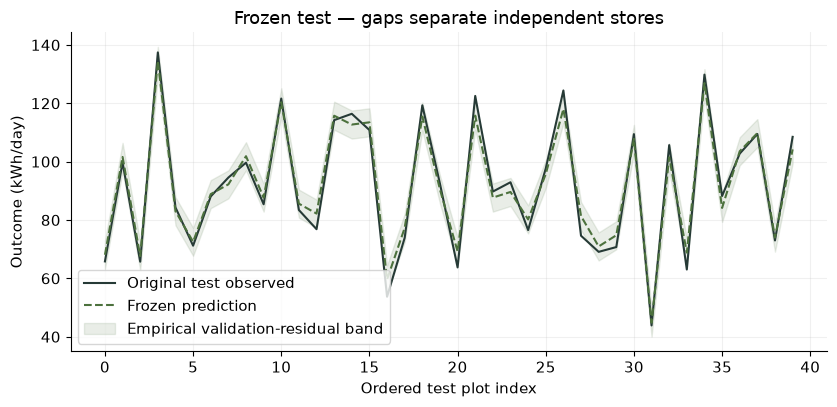

In [12]:
shifted=partition(make_dataset(PROJECT,SEED,shift=True),'test')
x_shift,y_shift=arrays(shifted)
shift_prediction=frozen.model.predict(x_shift)
print('Shifted population:',metrics(y_shift,shift_prediction))
print('Shifted empirical-band coverage:',float(np.mean(np.abs(shift_prediction-y_shift)<=radius)))
boundaries=[i for i in range(1,len(test)) if test[i]['entity'] != test[i-1]['entity']]
plot_y=np.insert(y_test,boundaries,np.nan)
plot_p=np.insert(final_prediction,boundaries,np.nan)
fig,ax=plt.subplots()
ax.plot(plot_y,label='Original test observed',color=COLORS['actual'])
ax.plot(plot_p,'--',label='Frozen prediction',color=COLORS['model'])
ax.fill_between(np.arange(len(plot_p)),plot_p-radius,plot_p+radius,color=COLORS['model'],alpha=.12,label='Empirical validation-residual band')
ax.set(title='Frozen test — gaps separate independent stores',xlabel='Ordered test plot index',ylabel=f'Outcome ({UNITS})');ax.legend(loc='best');plt.tight_layout();plt.show()

## Checks
Run the companion unit tests after rebuilding the model. Then try the following development-only experiments; use a fresh protocol if you change the model after seeing a final test.

In [13]:
import unittest
from test_workshop import WorkshopChecks
suite=unittest.defaultTestLoader.loadTestsFromTestCase(WorkshopChecks)
result=unittest.TextTestRunner(verbosity=1).run(suite)
assert result.wasSuccessful()

.

.

.

.

.

...

.

.

.

.

----------------------------------------------------------------------
Ran 10 tests in 0.103s

OK


### Learning curves, regularization, and seed stability
Repeat prefixes of the training period (or whole training machines), not random partial snapshots of a group. Measure training and validation separately. More data or a smaller training loss can fail to help if representation, labels, or deployment assumptions are wrong.

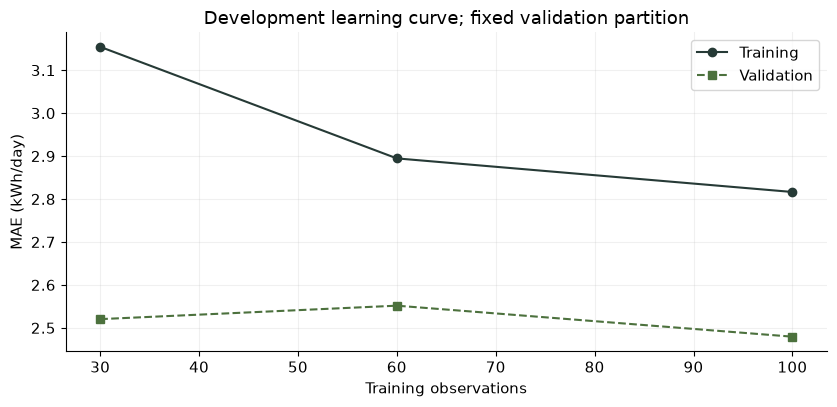

seed 42 {'mae': 2.4794957233793555, 'rmse': 3.101997753718827, 'bias': 0.48895624399376664}
seed 59 {'mae': 2.993111987846222, 'rmse': 3.6802591268156357, 'bias': -0.26668251473007415}
seed 76 {'mae': 3.024023759316619, 'rmse': 3.6422600105879246, 'bias': 0.09996620092741929}


In [14]:
curve=[]
for fraction in (.3,.6,1.):
    if classification:
        entities=sorted({r['entity'] for r in train})
        keep=set(entities[:max(2,int(len(entities)*fraction))])
        subset=[r for r in train if r['entity'] in keep]
    else:
        times=sorted({r['time'] for r in train})
        cutoff=times[max(0,int(len(times)*fraction)-1)]
        subset=[r for r in train if r['time']<=cutoff]
    xx,yy=arrays(subset)
    if classification and len(np.unique(yy))<2: continue
    m=pipeline_for(classification,.1,len(subset));m.fit(xx,yy)
    metric='log_loss' if classification else 'mae'
    curve.append((len(subset),metrics(yy,output(m,xx,classification),classification)[metric],metrics(y_val,output(m,x_val,classification),classification)[metric]))
fig,ax=plt.subplots()
ax.plot([r[0] for r in curve],[r[1] for r in curve],'o-',label='Training',color=COLORS['actual'])
ax.plot([r[0] for r in curve],[r[2] for r in curve],'s--',label='Validation',color=COLORS['model'])
ax.set(title='Development learning curve; fixed validation partition',xlabel='Training observations',ylabel='Log loss' if classification else f'MAE ({UNITS})');ax.legend();plt.tight_layout();plt.show()
for seed in (42,59,76):
    sample=make_dataset(PROJECT,seed);tr=partition(sample,'train');va=partition(sample,'validation');xx,yy=arrays(tr);vx,vy=arrays(va)
    m=pipeline_for(classification,.1,len(tr));m.fit(xx,yy)
    print('seed',seed,metrics(vy,output(m,vx,classification),classification))

### Keep preprocessing inside cross-validation
This small development search fits the complete imputation/scaling/model pipeline within every fold. It does not touch final labels. Machines use GroupKFold; demand uses explicit time-block indices across all stores; factory days use forward TimeSeriesSplit. Raw sklearn penalty values are searched here, not a guarantee of equivalent normalized λ in every fold.

In [15]:
from sklearn.model_selection import GridSearchCV, GroupKFold, TimeSeriesSplit, cross_val_score
if classification:
    groups=np.array([r['entity'] for r in train])
    cv=list(GroupKFold(3).split(x_train,y_train,groups))
    grid={'logisticregression__C':[.05,.5,5.]}
elif PROJECT=='demand':
    cv=[(np.array([i for i,r in enumerate(train) if r['time']<cut]), np.array([i for i,r in enumerate(train) if cut<=r['time']<cut+6])) for cut in (30,42,54)]
    grid={'ridge__alpha':[0.,10.,100.]}
else:
    cv=TimeSeriesSplit(3)
    grid={'ridge__alpha':[0.,10.,100.]}
search=GridSearchCV(pipeline_for(classification,.1,len(train)),grid,cv=cv,scoring='neg_log_loss' if classification else 'neg_mean_absolute_error',error_score='raise')
search.fit(x_train,y_train)
print('Training-only development search:',search.best_params_,'CV score:',search.best_score_)
if PROJECT=='energy':
    inner=GridSearchCV(pipeline_for(False),{'ridge__alpha':[0.,10.,100.]},cv=TimeSeriesSplit(2),scoring='neg_mean_absolute_error')
    outer=-cross_val_score(inner,x_train,y_train,cv=TimeSeriesSplit(3),scoring='neg_mean_absolute_error')
    print('Nested forward development MAEs:',outer)
    print('Fold dispersion is not automatically a confidence interval.')

Training-only development search: {'ridge__alpha': 0.0} CV score: -2.2635508049612003
Nested forward development MAEs: [2.32605949 2.45472647 2.00986646]
Fold dispersion is not automatically a confidence interval.


### SVD/PCA bridge: reconstruct, then ask whether variance helps prediction
This is a verified numerical side lesson, not a completed 3D spectral curriculum. SVD applies to rectangular matrices. PCA fits directions from training X without using y; high input variance alone does not establish predictive usefulness.

In [16]:
from sklearn.decomposition import PCA
centered=x_train-x_train.mean(axis=0)
u,s,vt=np.linalg.svd(centered,full_matrices=False)
np.testing.assert_allclose((u*s)@vt,centered,atol=1e-10)
np.testing.assert_allclose(vt@vt.T,np.eye(vt.shape[0]),atol=1e-10)
print('Training design condition number:',float(np.linalg.cond(centered)))
print('Rectangular SVD shape:',centered.shape,'reconstruction maximum error:',float(np.max(np.abs((u*s)@vt-centered))))
pca=make_pipeline(StandardScaler(),PCA(n_components=1))
pca.fit(x_train)  # never fit PCA to validation/test inputs
print('Training-only first-component explained variance:',float(pca[-1].explained_variance_ratio_[0]))

Training design condition number: 1.1854506542820145
Rectangular SVD shape: (100, 2) reconstruction maximum error: 1.5543122344752192e-15
Training-only first-component explained variance: 0.5842099021215922


## Next Steps
1. Without opening the answer key, write a new prediction contract and feature-availability table for a different domain.
2. Explain why the split represents that deployment.
3. Rebuild the baseline and pipeline, then freeze your protocol.
4. Write a conditional decision memo: evidence, assumptions, errors, uncertainty, owner, monitoring cadence, fallback, rollback.
5. Return after a delay with a different seed and explain the workflow without copying.

Opening this notebook shows worked results; count independent practice only on a fresh task before reading solutions. Real expert, novice, screen-reader, physical-device, and low-end performance reviews remain pending. See README and DATA.md for limitations and references.